## Hydrodynamic model of the Southern North Sea

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch
import optuna
import ast


# dataset helper
from helper import get_wl_point_obs, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Data Loading

In [3]:
# folders
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/Mesh_8000_elems_HD_v2.mesh"
obs_fldr = "datasets/observations/"

msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

# load simulation
ds = dfs.read(time=slice("2022-01-01", "2023-10-30"))
valid_nodes = ~np.isnan(ds["Surface elevation"].values).any(axis=0)
H, U, V = [
    torch.tensor(ds[var].values[:, valid_nodes], dtype=torch.float32)
    for var in ("Surface elevation", "U velocity", "V velocity")
]
print("Simulation data loaded successfully.")

# load observations
high_fidelity = {"Dover", "ZeebruggeWielingendok", "NWA", "K141"}
stations = [obs for obs in get_wl_point_obs() if obs.name in high_fidelity]
measurements = torch.tensor(
    extract_water_level_measurements(stations, ds_time=ds.time, obs_fldr=obs_fldr),
    dtype=torch.float32,
)
print("Observation data loaded successfully.\n")

# print array shapes
for name, x in {"H": H, "U": U, "V": V, "Measurements": measurements}.items():
    print(f"{name} shape:", x.shape, ".\tNumber of NaNs:", torch.isnan(x).sum().item())

del dfs

Simulation data loaded successfully.
Observation data loaded successfully.

H shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
U shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
V shape: torch.Size([32064, 8533]) .	Number of NaNs: 0
Measurements shape: torch.Size([32064, 4]) .	Number of NaNs: 25037


## Hyperparameters

In [4]:
##########################################################################################################
################## FIXED HYPERPARAMETERS FOR TUNING RUNS #################################################
##########################################################################################################
ERRORS = []

# DataManager
LAGS = 24
TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing
COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)
MASKING_TYPE = "mask_data"  # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 1e-3    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)
BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training

##########################################################################################################
################## GRID OF HYPERPARAMETERS TO TUNE #######################################################
##########################################################################################################

# Architecture
TRANSFORMER_TYPE = ["transformer", "transformer_hidden_mask", "transformer_attn_mask", "transformer_learned_mask"]  
DOUBLE_CHANNEL = [True, False]                  # whether to use double channel input (H,U,V) or single channel (H only)
MAX_ENCODER_DEPTH = 4                           # number of encoder layers
HIDDEN_SIZE = [16,32,48,64]                        # hidden size for encoder and decoder layers
N_HEADS = 4                                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = [32,48,64,128]                   # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = ["cnn","mlp"]                         # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = ["64", "64,96", "96"]    # sampled as strings; parsed to int list in create_model
MAX_DROPOUT = 0.2                               # dropout rate for encoder and decoder layers

N_OPTUNA_TRIALS = 100  # number of Optuna trials to run for hyperparameter tuning

print("Total number of hyperparameter combinations to explore:", len(TRANSFORMER_TYPE) * len(DOUBLE_CHANNEL) * len(HIDDEN_SIZE) * len(DIM_FEEDFORWARD) * len(DECODER) * len(DECODER_HIDDEN_SIZES) * 4 * 3)

Total number of hyperparameter combinations to explore: 9216


## DataManager

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]


Data shapes after preparation:
Train:	 torch.Size([25651, 24, 4]) -> torch.Size([25651, 120])
Val:	 torch.Size([3206, 24, 4]) -> torch.Size([3206, 120])
Test:	 torch.Size([3207, 24, 4]) -> torch.Size([3207, 120])


## Training

In [6]:
# create model from Optuna trial
def create_model(trial):
    return dict(
        encoder              = trial.suggest_categorical('encoder', TRANSFORMER_TYPE),
        double_channels      = trial.suggest_categorical('double_channels', DOUBLE_CHANNEL),
        encoder_depth        = trial.suggest_int('encoder_depth', 1, MAX_ENCODER_DEPTH),
        n_heads              = N_HEADS,
        dim_feedforward      = trial.suggest_categorical('dim_feedforward', DIM_FEEDFORWARD),
        hidden_size          = trial.suggest_categorical('hidden_size', HIDDEN_SIZE),
        input_length         = LAGS,
        decoder              = trial.suggest_categorical('decoder', DECODER),
        decoder_hidden_sizes = [int(x) for x in trial.suggest_categorical('decoder_hidden_sizes', DECODER_HIDDEN_SIZES).split(',')],
        dropout              = trial.suggest_float('dropout', 0.0, MAX_DROPOUT, step=0.1),
        input_size           = nn_input_shape,
        output_size          = nn_output_shape,
    )

# objective function for Optuna to minimize (validation loss)
def objective(trial):

    # create model from trial hyperparameters
    model_args = create_model(trial)
    mshred = mSHRED(args=model_args).to(device)
    
    # fit model and get training and validation losses
    _ , valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=False,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE, masking_type=MASKING_TYPE,
    )

    # Evaluating model on test set using the best model from training (early stopping)
    test_error = evaluate_model(
        evaluate, mshred, train_dataset, val_dataset, test_dataset,
        model=f"(mSHRED)", type=f"{model_args}", masking_type=MASKING_TYPE
    )

    # Logging errors and disply the last row
    ERRORS.append(test_error)                   # log test error for current trial
    dataframe_errors = pd.DataFrame(ERRORS)     # create dataframe from logged errors
    #display(dataframe_errors.tail(1))          # display last row of errors dataframe
    dataframe_errors.to_csv('dataframe_errors_optuna.csv', index=False)     # save errors to csv after each trial

    # return validation error for Optuna to minimize
    return float(test_error["val-mse"])

In [ ]:
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=N_OPTUNA_TRIALS)

[I 2026-05-07 00:38:05,566] A new study created in memory with name: no-name-b96104ce-483f-413d-9578-705ee528d50f
[I 2026-05-07 00:55:28,872] Trial 0 finished with value: 0.004219117451882903 and parameters: {'encoder': 'transformer_attn_mask', 'double_channels': False, 'encoder_depth': 2, 'dim_feedforward': 64, 'hidden_size': 16, 'decoder': 'mlp', 'decoder_hidden_sizes': '64,96', 'dropout': 0.0}. Best is trial 0 with value: 0.004219117451882903.
[I 2026-05-07 01:08:51,750] Trial 1 finished with value: 0.004200016872027382 and parameters: {'encoder': 'transformer_attn_mask', 'double_channels': False, 'encoder_depth': 4, 'dim_feedforward': 64, 'hidden_size': 32, 'decoder': 'cnn', 'decoder_hidden_sizes': '64', 'dropout': 0.0}. Best is trial 1 with value: 0.004200016872027382.
[I 2026-05-07 01:18:22,670] Trial 2 finished with value: 0.0042096056533680315 and parameters: {'encoder': 'transformer_learned_mask', 'double_channels': True, 'encoder_depth': 4, 'dim_feedforward': 48, 'hidden_size

## Results

In [19]:
dataframe_errors = pd.read_csv("dataframe_errors_optuna.csv")
dataframe_errors = dataframe_errors.sort_values(by="test-mre")

# Parse the 'type' column string into a dict and expand into columns
type_df = dataframe_errors['type'].apply(lambda x: ast.literal_eval(x)).apply(pd.Series)
# Remove columns with the same value across all rows
type_df = type_df.drop(columns=['input_size', 'output_size', 'input_length', 'n_heads'])
# Add the test-mre column
type_df['test-mre'] = dataframe_errors['test-mre'].values

print("Dataframe with hyperparameters ordered by test MRE:")
display(type_df.sort_values("test-mre").head(8))

Dataframe with hyperparameters ordered by test MRE:


,encoder,double_channels,encoder_depth,dim_feedforward,hidden_size,decoder,decoder_hidden_sizes,dropout,test-mre
42,transformer_attn_mask,False,4,64,32,cnn,[64],0.0,0.155744
81,transformer_attn_mask,False,4,128,16,cnn,[96],0.0,0.155996
78,transformer_attn_mask,False,3,48,16,mlp,[64],0.0,0.156142
70,transformer_attn_mask,False,2,64,16,cnn,[64],0.0,0.156321
46,transformer_learned_mask,True,1,128,16,mlp,[64],0.0,0.156509
0,transformer_learned_mask,True,1,48,64,mlp,[64],0.0,0.156748
77,transformer_attn_mask,False,4,48,16,cnn,[64],0.0,0.157054
15,transformer_attn_mask,True,3,48,32,cnn,[96],0.1,0.157408


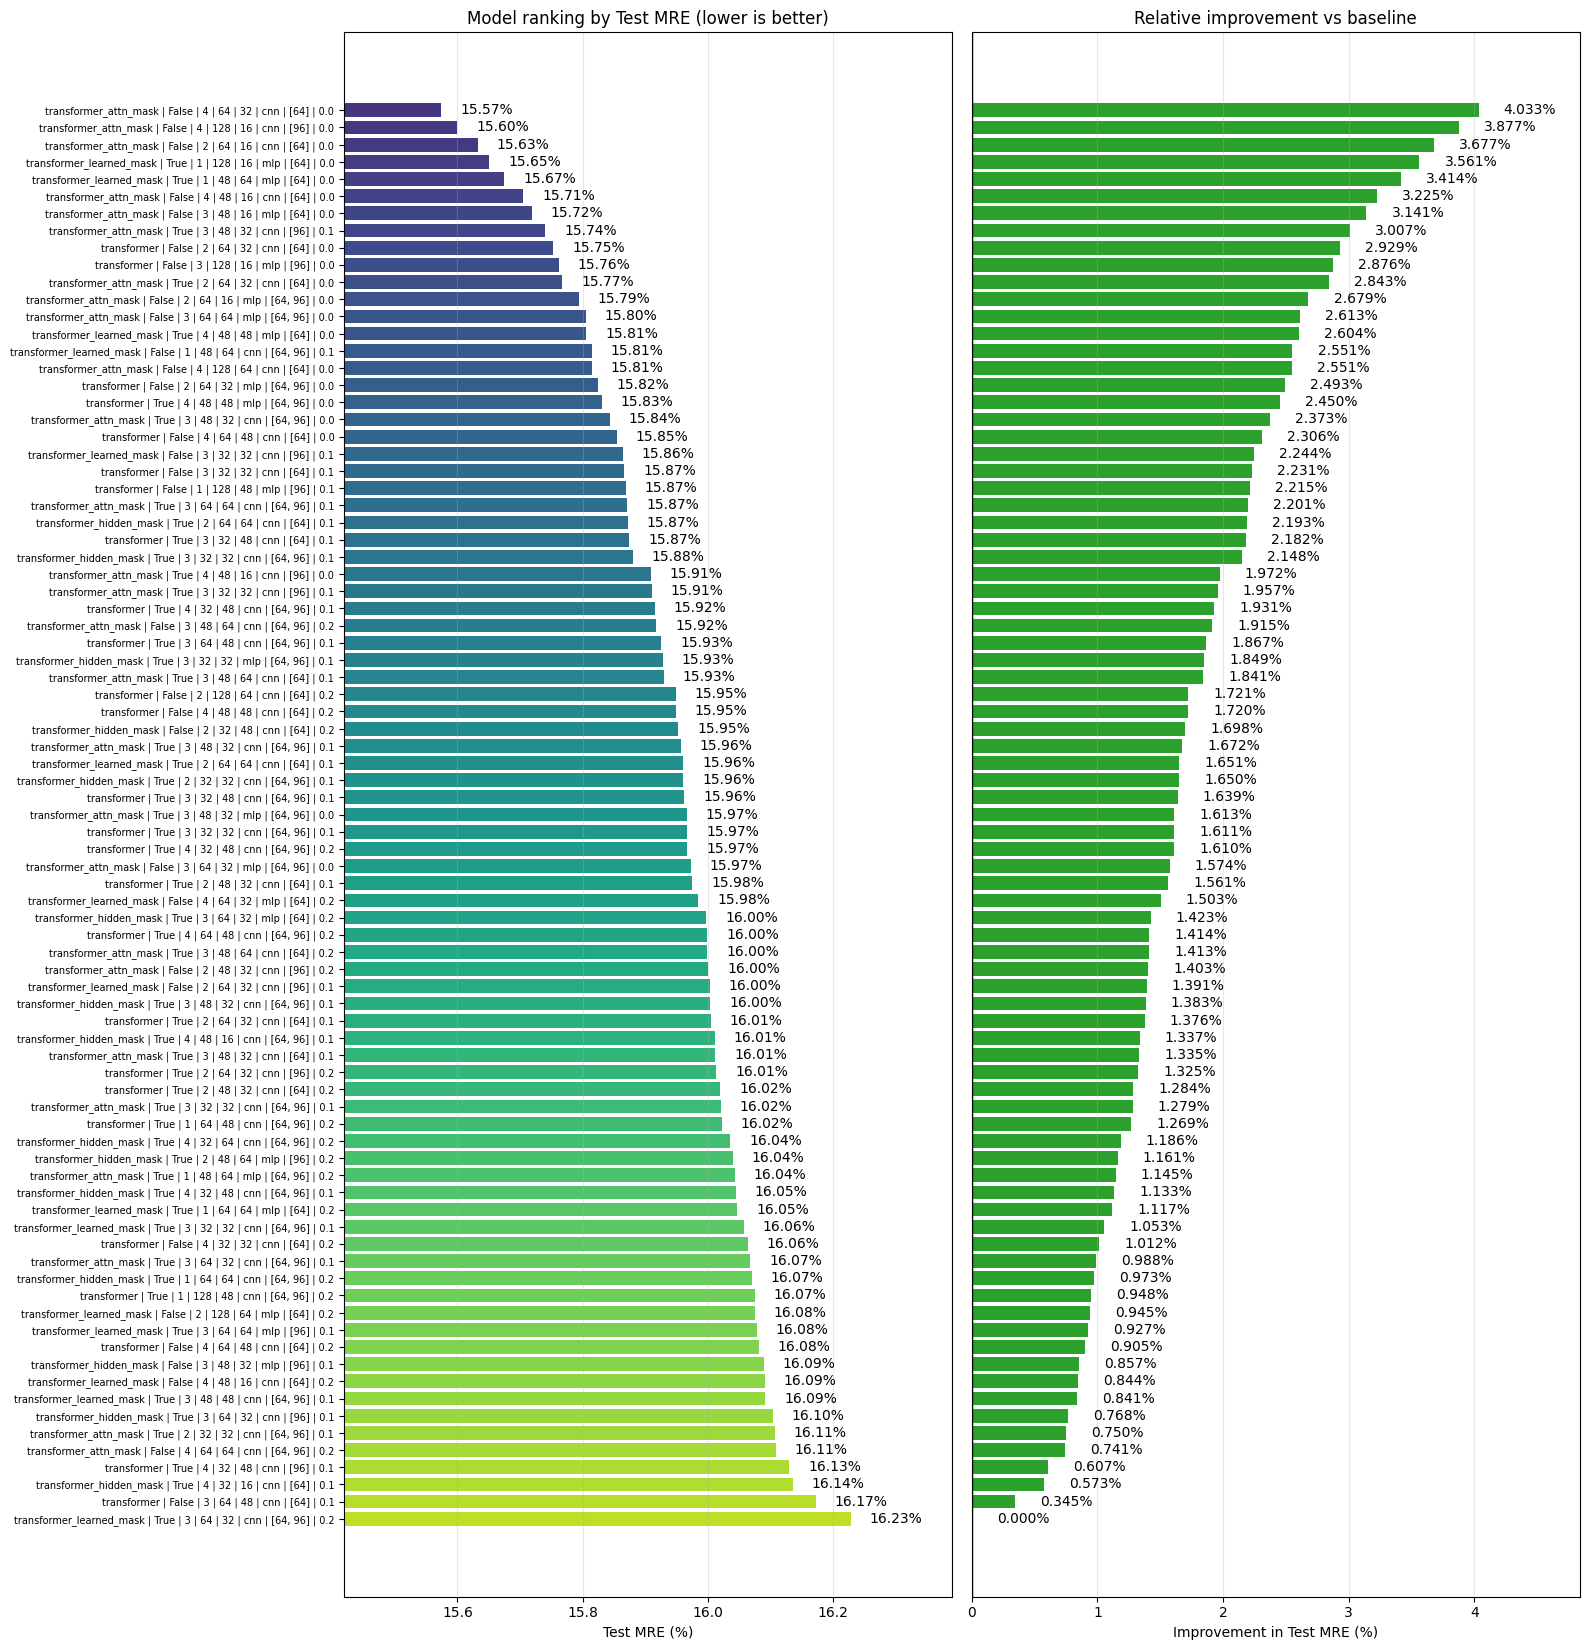

In [18]:
# Convert any list-valued columns to strings so they are hashable for groupby
hyperparam_cols = [c for c in type_df.columns if c != "test-mre"]
for col in hyperparam_cols:
    if type_df[col].apply(lambda x: isinstance(x, list)).any():
        type_df[col] = type_df[col].apply(lambda x: str(x) if isinstance(x, list) else x)

# Average duplicated hyperparameter configurations
df_plot = (
    type_df
    .groupby(hyperparam_cols, as_index=False)["test-mre"]
    .mean()
    .sort_values(by="test-mre")
    .reset_index(drop=True)
)

# Build label from all hyperparameter columns (values only, no keys)
df_plot["label"] = df_plot[hyperparam_cols].apply(
    lambda row: " | ".join(f"{v}" for k, v in row.items()), axis=1
)

df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
baseline_test_mre = df_plot["test-mre"].iloc[-1]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

n = len(df_plot)
fig_height = max(8, n * 0.2)
fig, axes = plt.subplots(1, 2, figsize=(16, fig_height))

# --- Left: Test MRE ranking (with labels) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, n))
axes[0].barh(df_plot["label"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)
axes[0].tick_params(axis="y", labelsize=7)
axes[0].set_xlim(min(df_plot["test-mre_%"]) * 0.99, max(df_plot["test-mre_%"]) * 1.01)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=10)

# --- Right: Improvement (no y-axis labels) ---
imp_colors = [
    "tab:blue" if "Normal_training" in lbl else ("tab:green" if x >= 0 else "tab:red")
    for lbl, x in zip(df_plot["label"], df_plot["improvement_vs_T0_%"])
]
axes[1].barh(df_plot["label"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)
axes[1].set_xlim(min(df_plot["improvement_vs_T0_%"]) * 1, max(df_plot["improvement_vs_T0_%"]) * 1.2)

# Hide y-axis labels and ticks on the right plot
axes[1].set_yticklabels([])
axes[1].tick_params(axis="y", left=False)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.2 if v >= 0 else -0.6), i, f"{v:.3f}%", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("hyperparams.png", dpi=150, bbox_inches="tight")
plt.show()

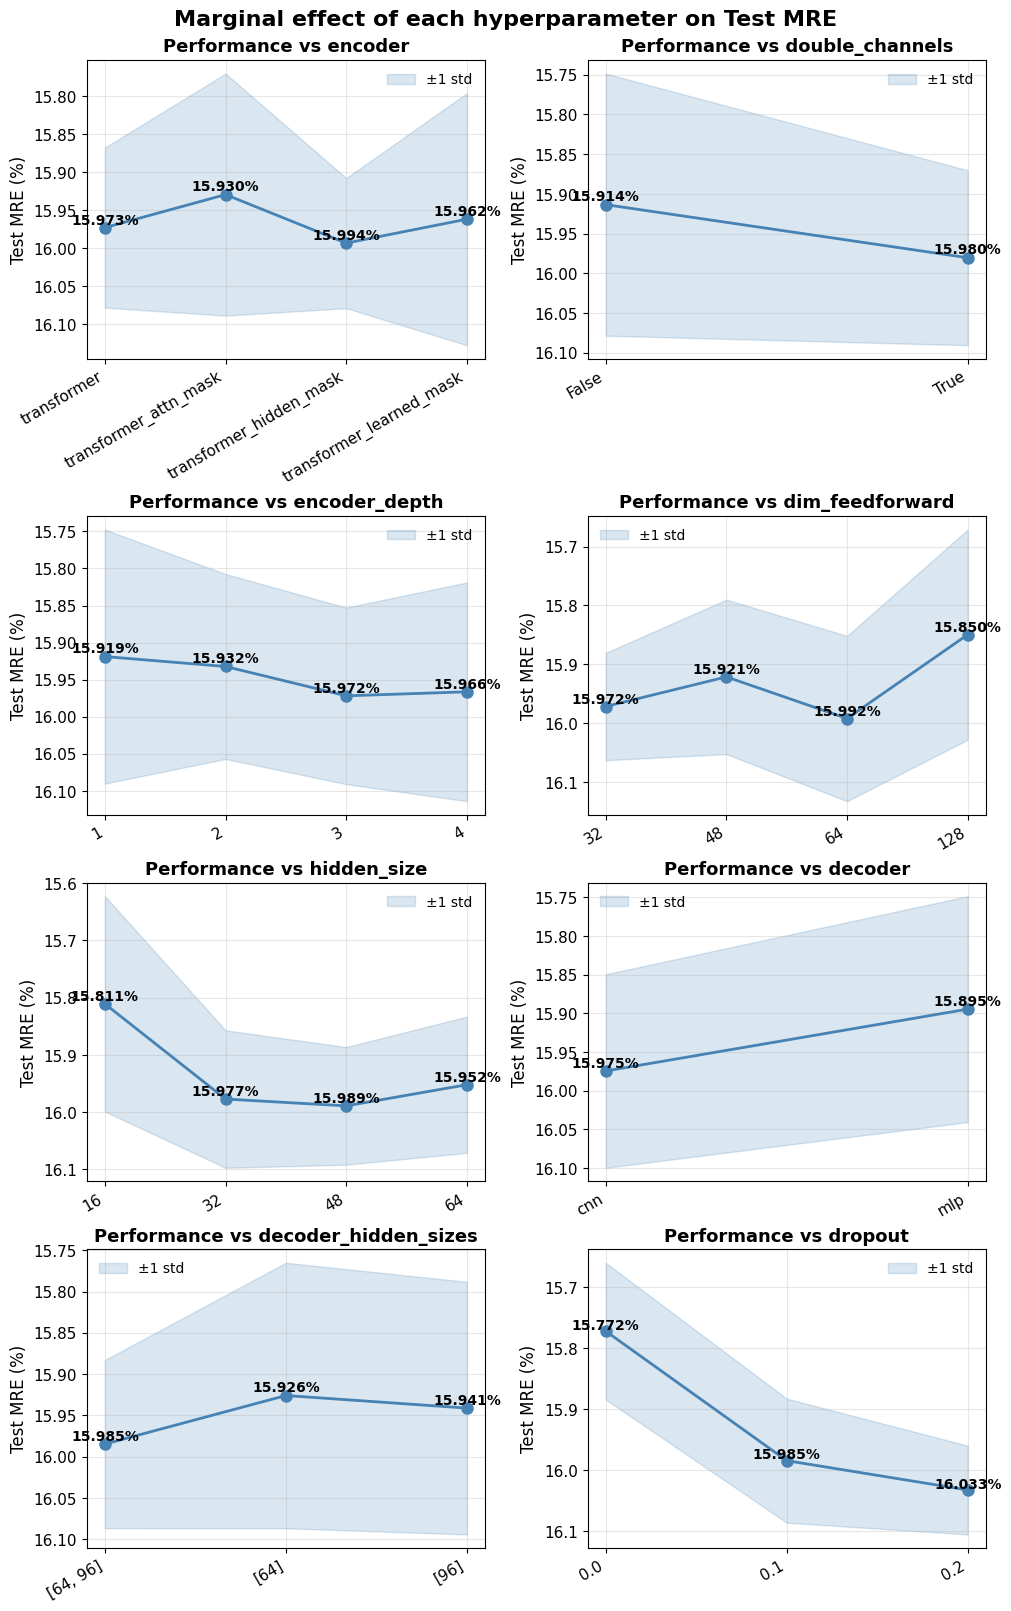

In [16]:
n_rows = 4
n_cols = int(np.ceil(len(hyperparam_cols) / n_rows))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), constrained_layout=True)
axes = axes.flatten()

for idx, col in enumerate(hyperparam_cols):
    ax = axes[idx]

    perf = type_df.groupby(col)["test-mre"].agg(["mean", "std"]).reset_index()
    perf = perf.sort_values(col)

    x_vals = list(range(len(perf)))

    mean_pct = perf["mean"] * 100
    std_pct  = perf["std"]  * 100

    ax.plot(x_vals, mean_pct, marker="o", linewidth=2, markersize=8, color="steelblue")
    ax.fill_between(
        x_vals,
        mean_pct - std_pct,
        mean_pct + std_pct,
        alpha=0.2, color="steelblue", label="±1 std"
    )

    ax.set_xticks(x_vals)
    ax.set_xticklabels(perf[col].astype(str).tolist(), rotation=30, ha="right", fontsize=11)
    
    ax.set_ylabel("Test MRE (%)", fontsize=12)
    ax.set_title(f"Performance vs {col}", fontsize=13, fontweight="bold")
    ax.tick_params(axis="y", labelsize=11)
    ax.grid(alpha=0.3)
    ax.invert_yaxis()

    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=10, loc="best", frameon=False)

    y_offset = std_pct.max() * 0.03
    for x, (_, row) in zip(x_vals, perf.iterrows()):
        ax.text(x, row["mean"] * 100 - y_offset, f"{row['mean'] * 100:.3f}%",
                ha="center", fontsize=10, fontweight="bold")

for idx in range(len(hyperparam_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Marginal effect of each hyperparameter on Test MRE", fontsize=16, fontweight="bold")
plt.savefig("hyperparam_marginal_effects.png", dpi=150, bbox_inches="tight")
plt.show()

## Run 1

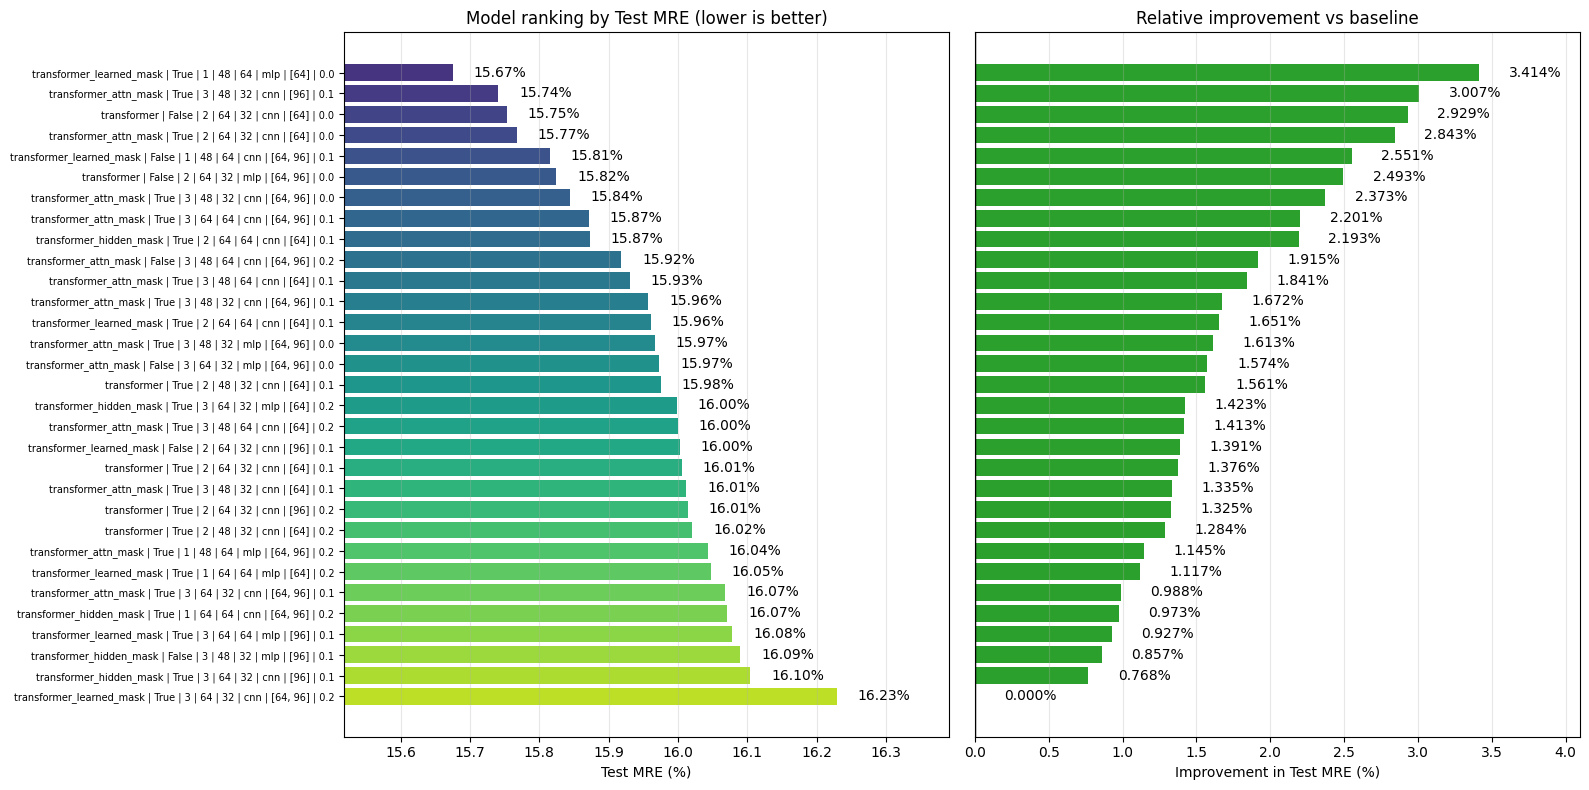

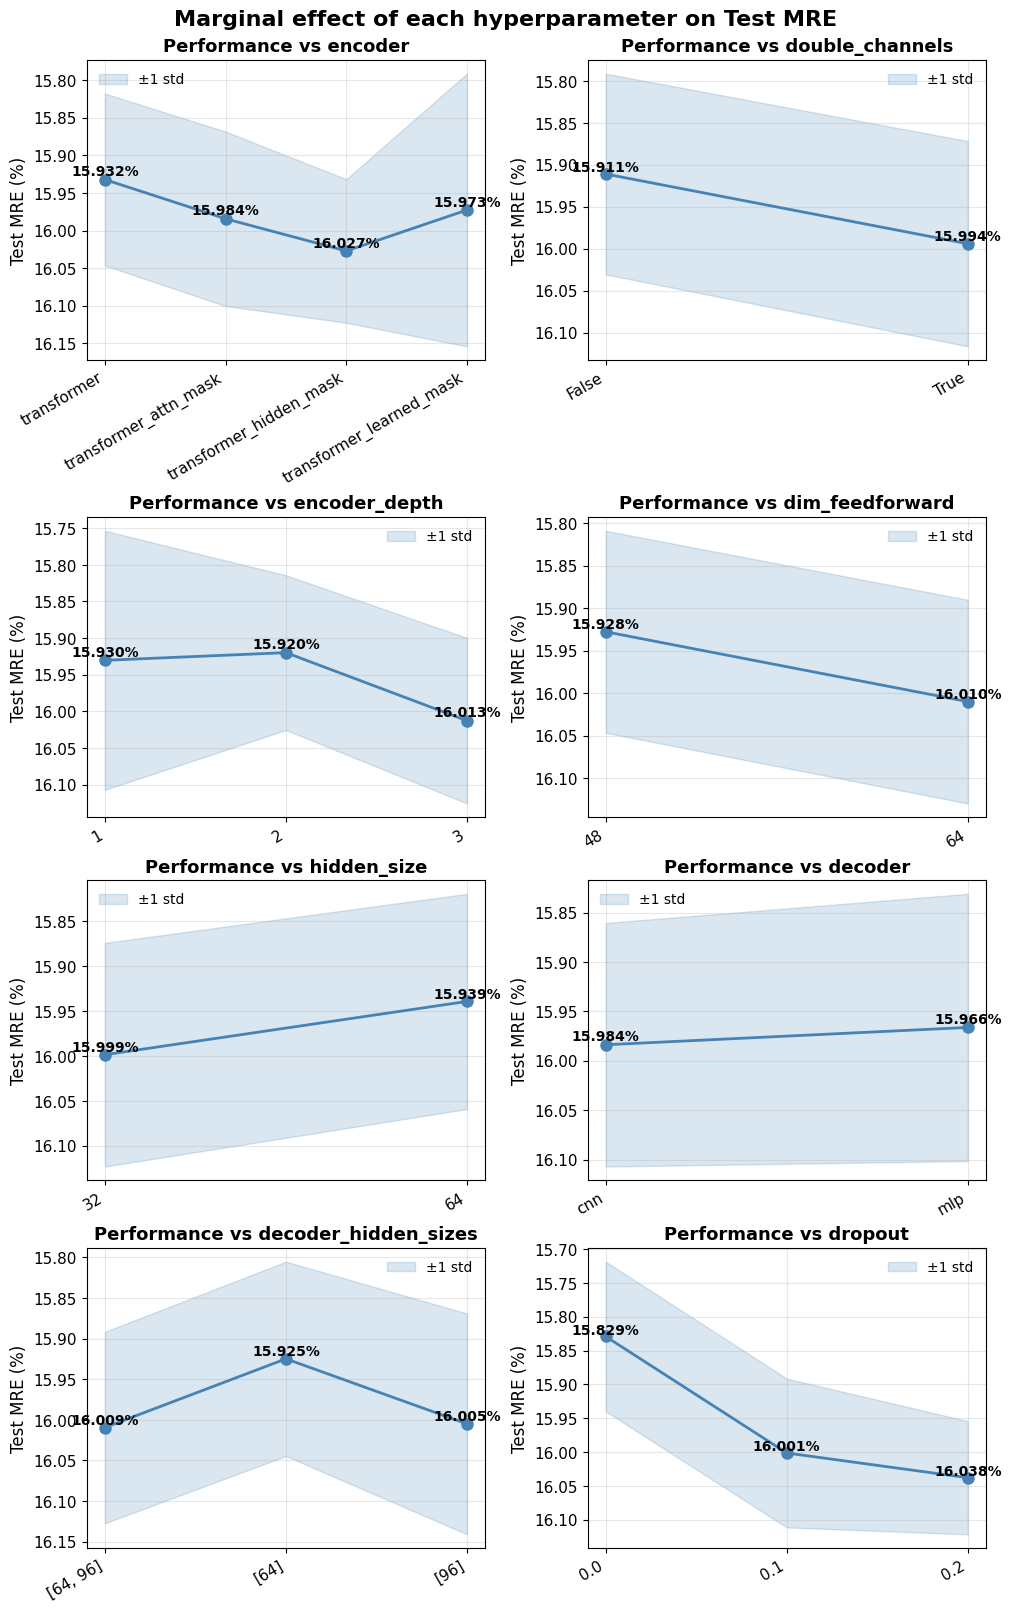

## Run 2

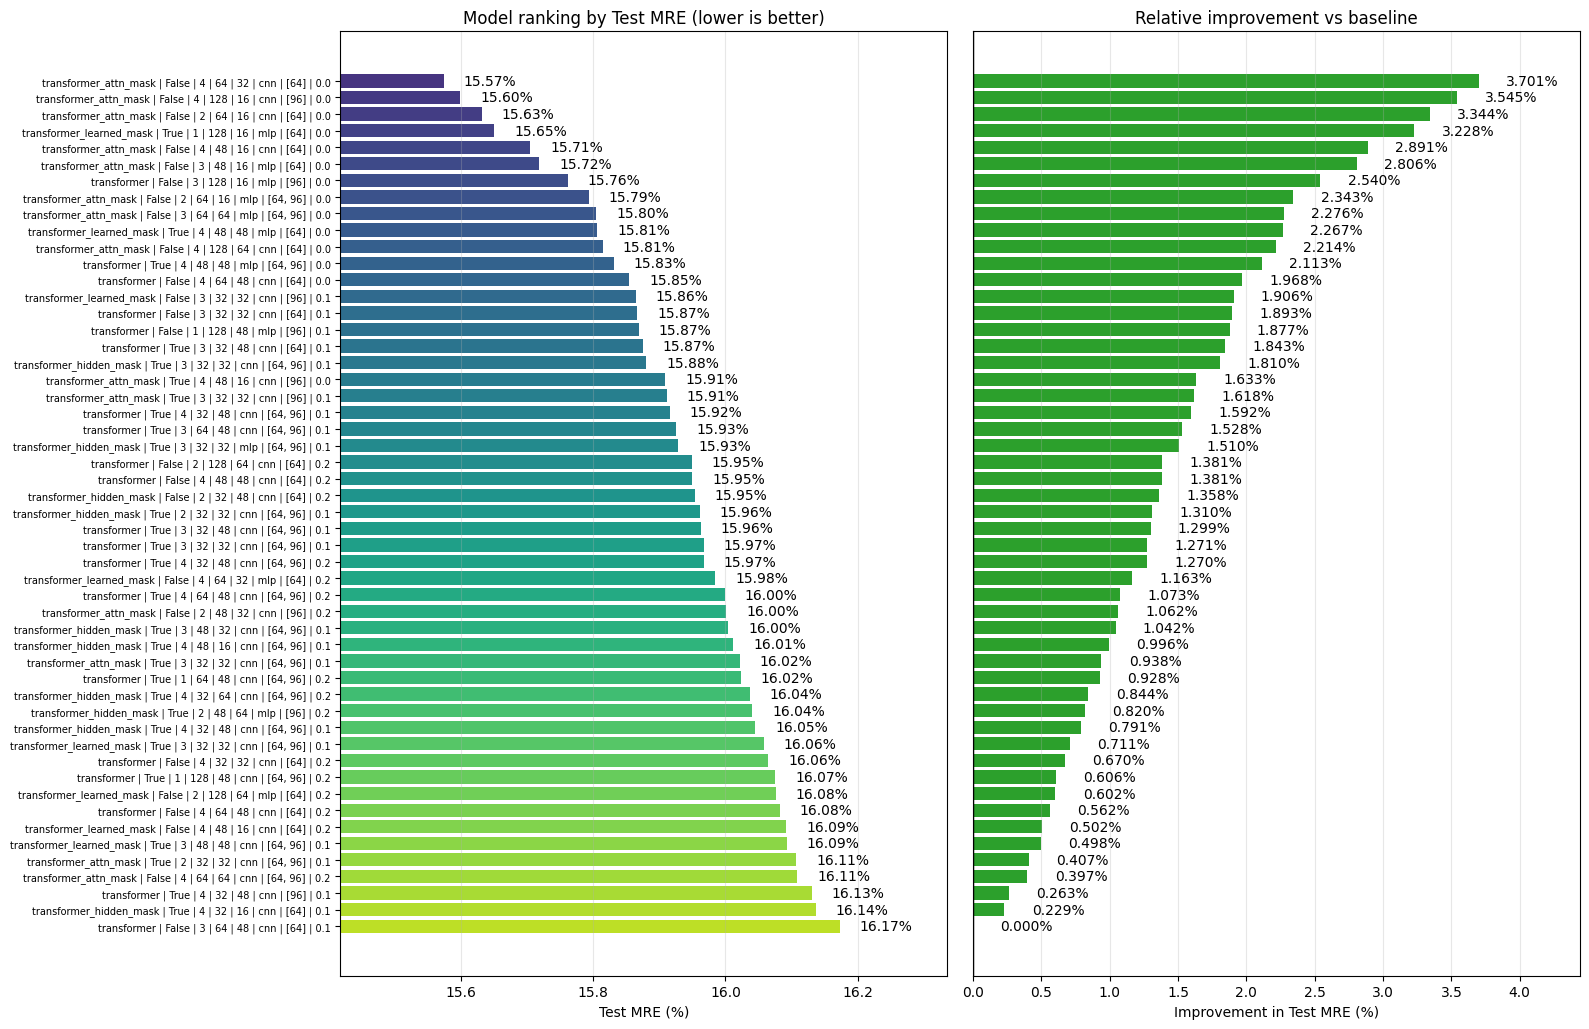

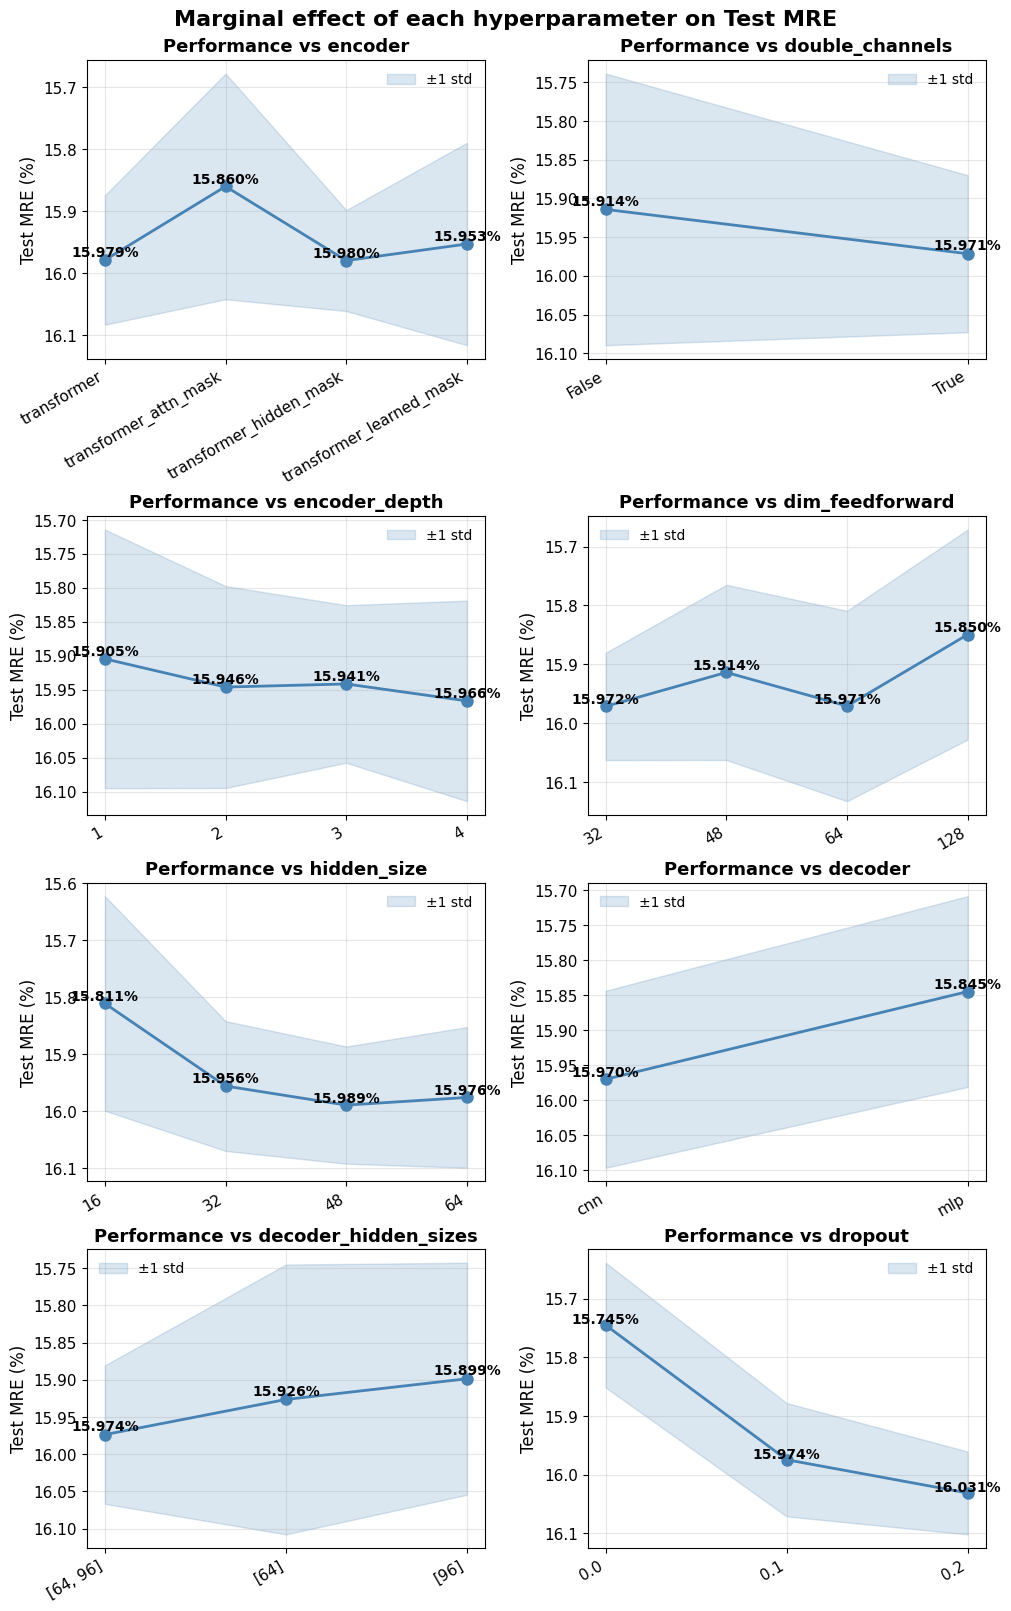

## Run All


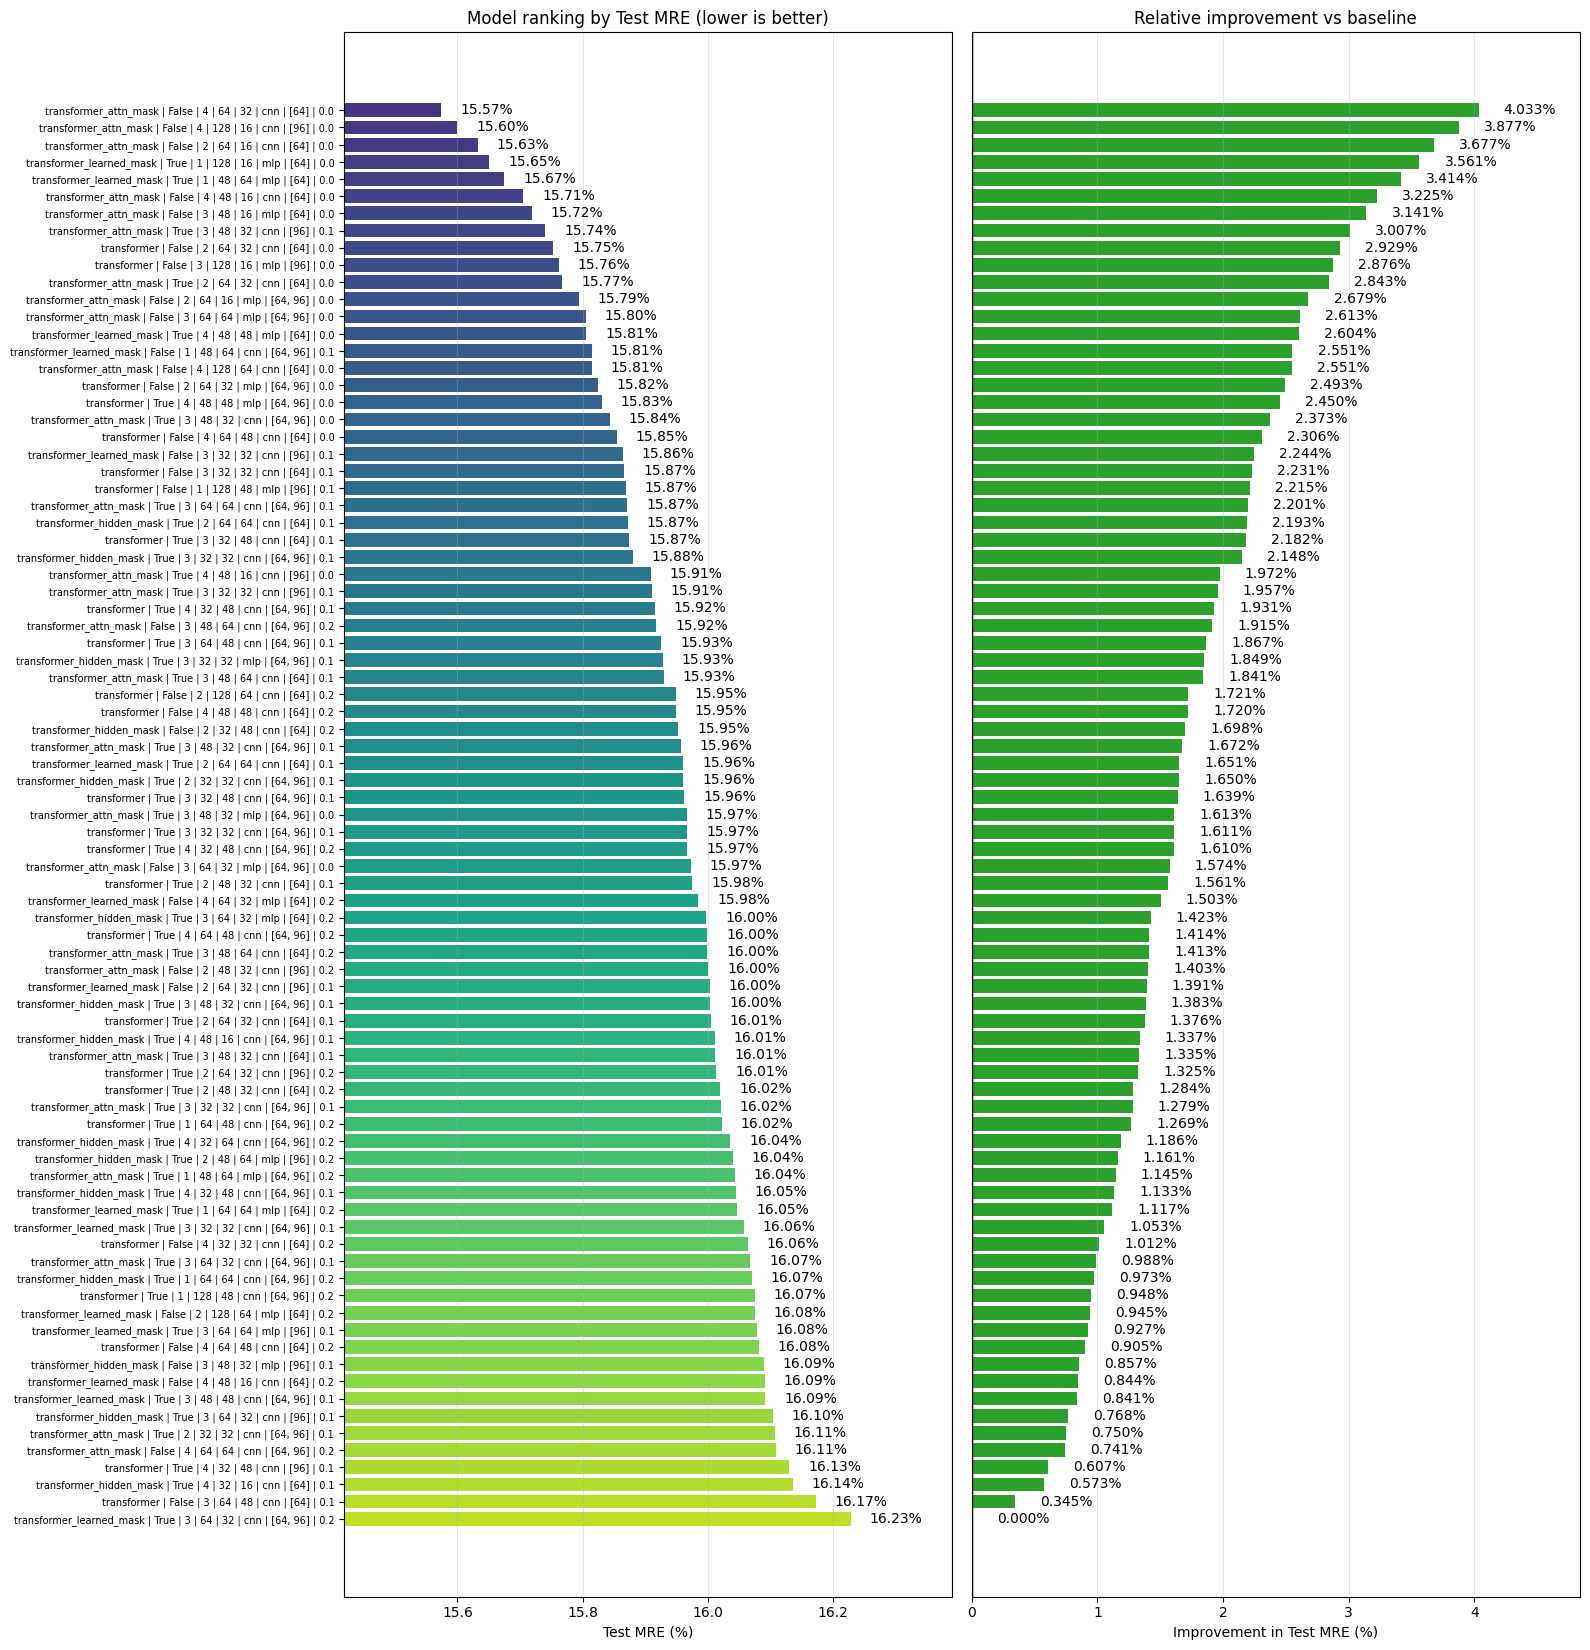
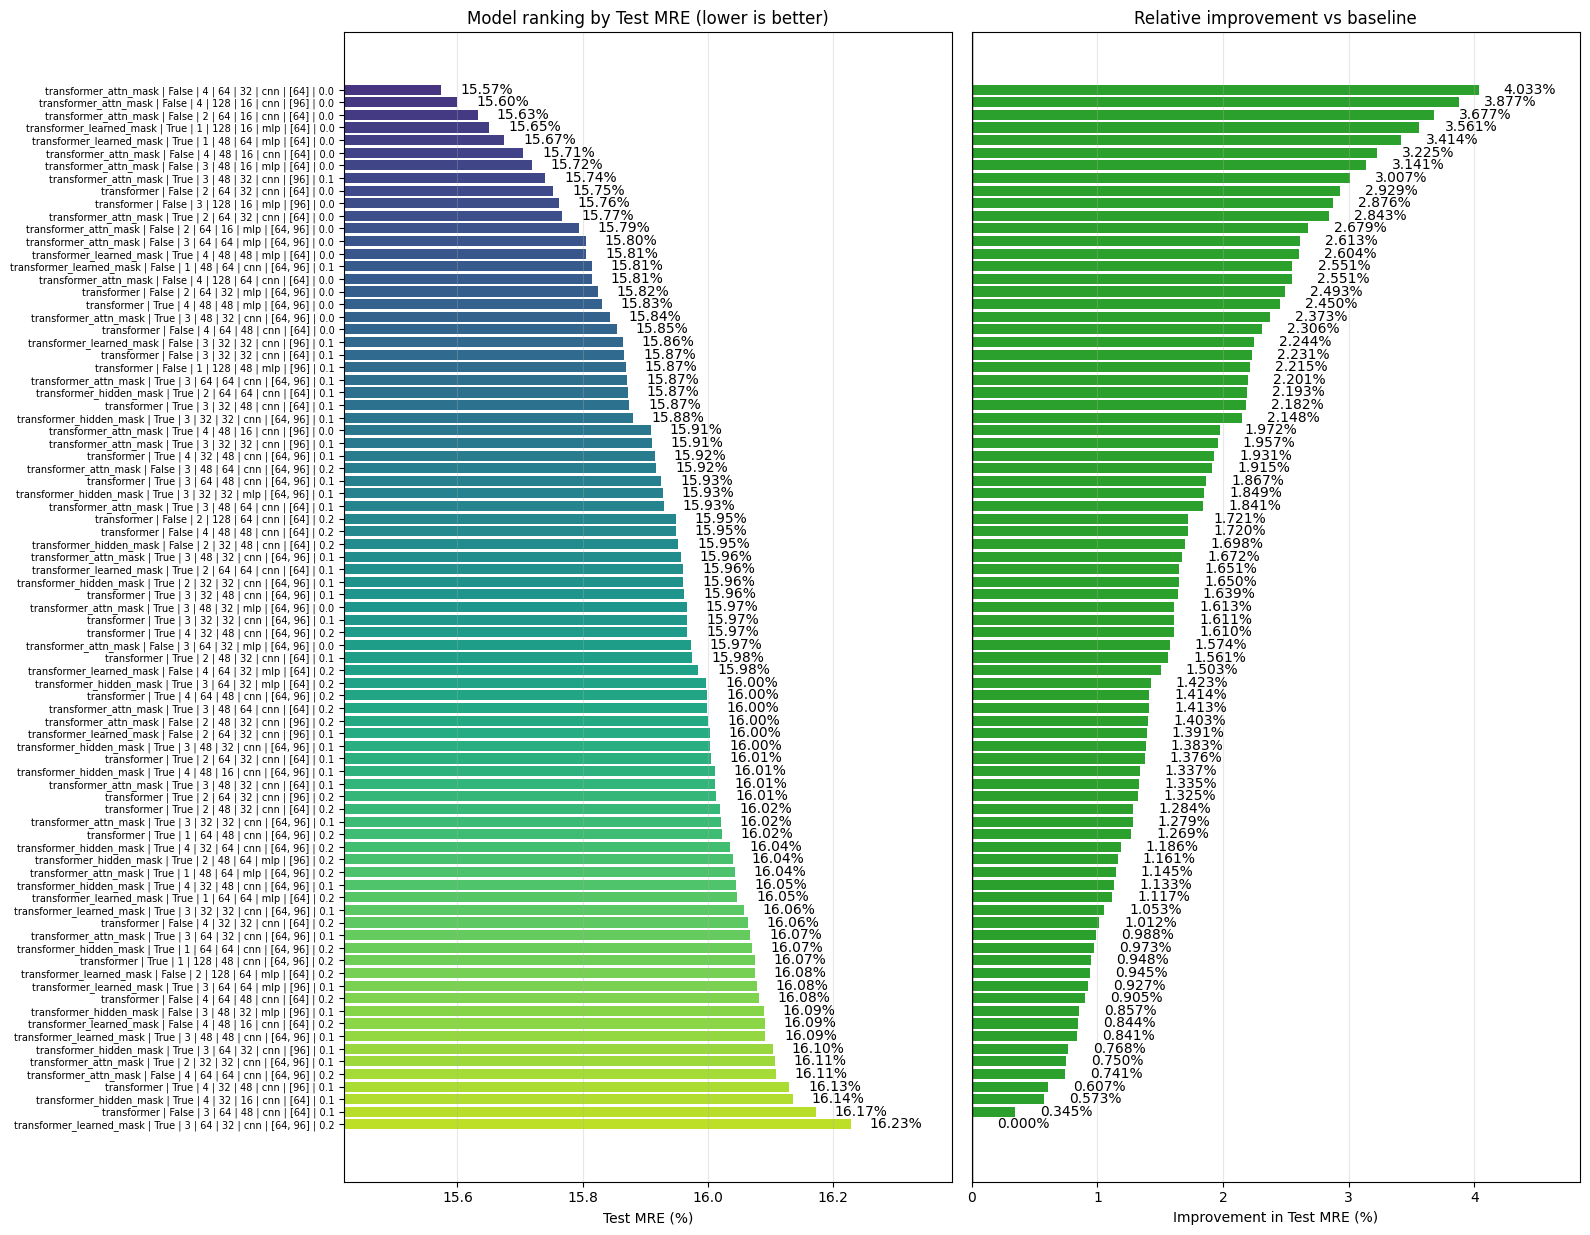

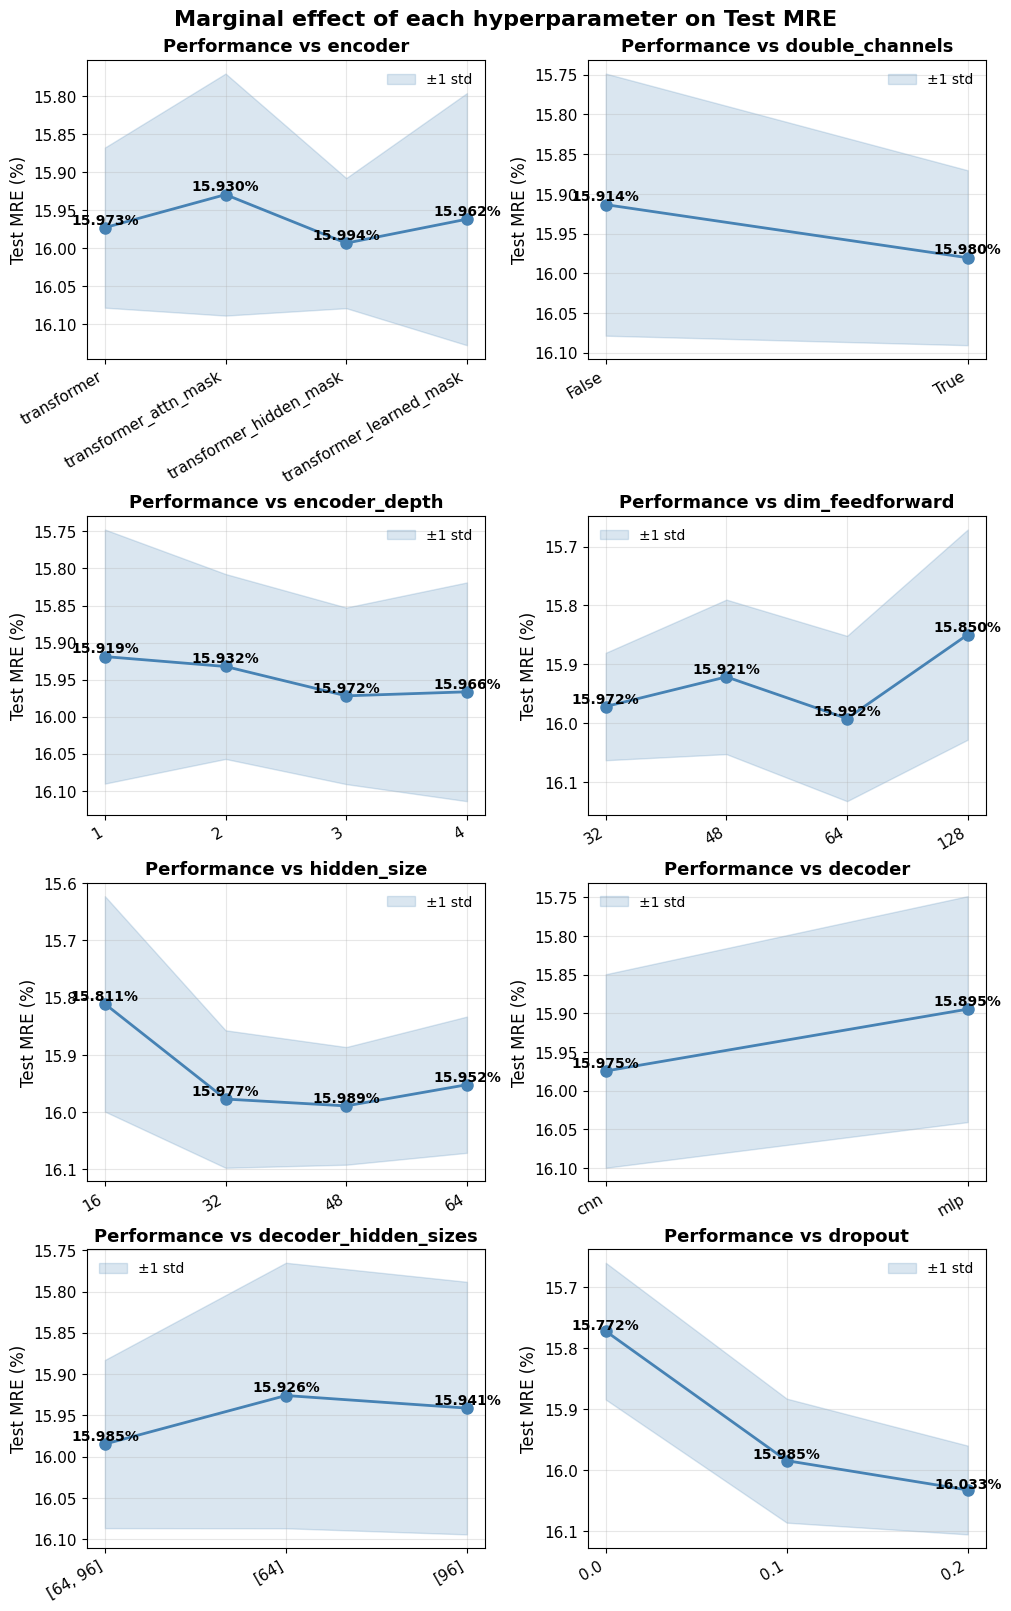